# Foundations 3: Functions and graphs

*Learning path: foundations, part 3 of 9.* [Index](README.md) · Previous: [Algebra](02-algebra.ipynb) · Next: [Polynomials](04-polynomials.ipynb)

A graph turns a formula into a picture. This lesson explains Galileo's plotting commands argument by argument, and
uses them to understand functions. You will learn

* how `plot` works, and how to label the axes, add a title and name the curves,
* how to read a graph: zeros, maxima, where a function is undefined,
* how shifting and stretching change a graph,
* exponential and logarithm functions, and inverse functions,
* how to find where two graphs cross.

## 1. Anatomy of a plot

A function takes a number $x$ and gives a number $f(x)$. Its graph is the set of points $(x, f(x))$: for every $x$
on the horizontal axis, the height of the curve is $f(x)$.

The basic command is

```
plot(expression, variable, from, to)
```

* **expression**: what to draw, for example `x^2 - 2`;
* **variable**: the letter that runs along the horizontal axis, here `x`;
* **from**, **to**: the part of the horizontal axis to show.

Galileo computes the expression at 400 evenly spaced values of the variable between *from* and *to* and joins the
points. The vertical range is chosen automatically to fit the curve.

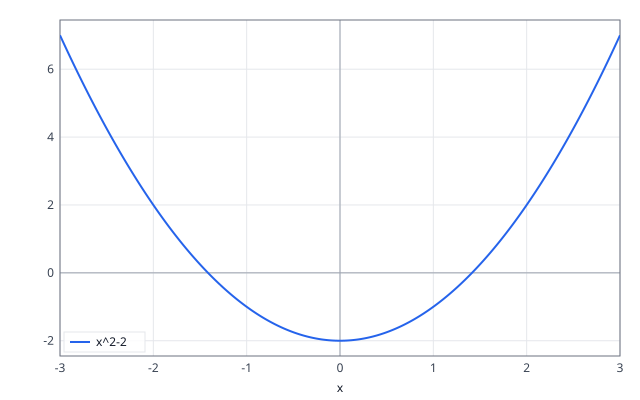

> `plot`: Plots one or more expressions of x.

In [1]:
plot(x^2 - 2, x, -3, 3)

How to read it: the horizontal axis is $x$ from $-3$ to $3$; the vertical axis is the value $x^2 - 2$. The curve is
lowest at $x = 0$, where it is $-2$, and crosses zero (the horizontal axis) at $x = \pm\sqrt{2} \approx \pm 1.41$.
The box in the top left corner (the *legend*) names the curve by the expression you typed.

A plot without axis labels is hard to read for anyone else, so from now on every plot gets labels. The commands
`labels`, `title` and `legend` each take a plot and return a labelled copy:

* `labels(p, "horizontal axis text", "vertical axis text")`,
* `title(p, "text")` puts a title above the plot,
* `legend(p, "name of curve 1", "name of curve 2", ...)` renames the curves in the legend.

Plots are values, so you can store one in a variable first. The plot is shown when a line that produces one is not
ended by `;`:

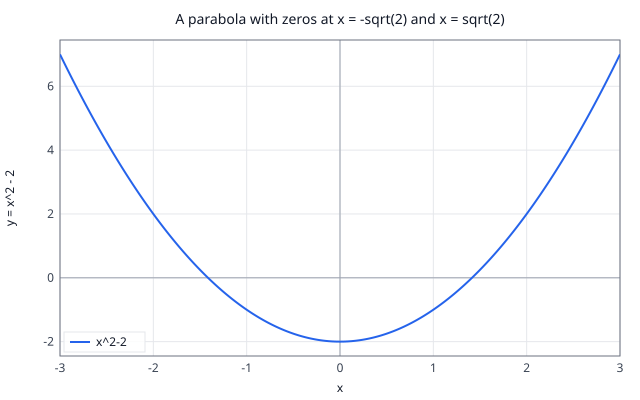

> `title`: A copy of plot p with a title or axis labels.

In [2]:
p = plot(x^2 - 2, x, -3, 3);
p = labels(p, "x", "y = x^2 - 2");
title(p, "A parabola with zeros at x = -sqrt(2) and x = sqrt(2)")

In JupyterLab the plot is interactive: hover to read off values, drag to zoom, double-click to reset.

### Several curves in one plot

List several expressions before the variable. Each curve gets its own colour and an entry in the legend:

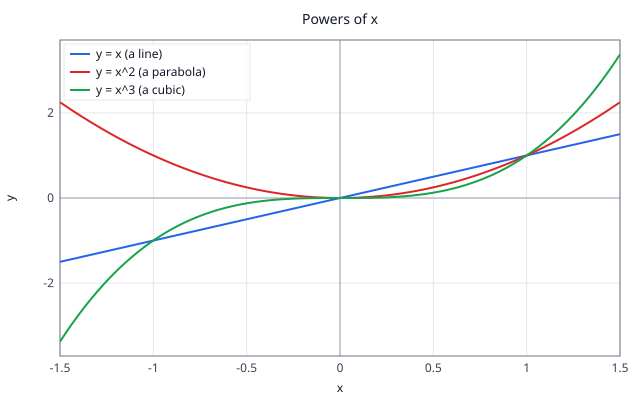

> `title`: A copy of plot p with a title or axis labels.

In [3]:
p = plot(x, x^2, x^3, x, -1.5, 1.5);
p = legend(p, "y = x (a line)", "y = x^2 (a parabola)", "y = x^3 (a cubic)");
labels(title(p, "Powers of x"), "x", "y")

All three pass through $(0, 0)$ and $(1, 1)$. For $|x| < 1$ higher powers are smaller; for $|x| > 1$ they are much
larger. Even powers ($x^2$) are symmetric around the vertical axis, odd powers ($x$, $x^3$) are symmetric around the
origin.

### Plotting your own function

A function defined with `:=` can be plotted by writing it applied to the plot variable:

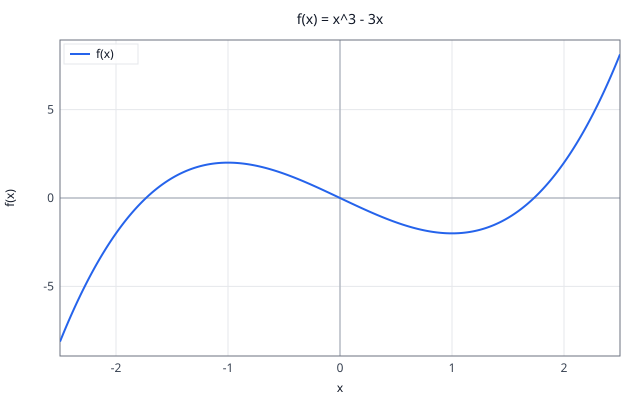

> `title`: A copy of plot p with a title or axis labels.

In [4]:
f(x) := x^3 - 3*x;
labels(title(plot(f(x), x, -2.5, 2.5), "f(x) = x^3 - 3x"), "x", "f(x)")

Reading the graph: $f$ has a local maximum near $x = -1$ (height 2), a local minimum near $x = 1$ (height $-2$), and
crosses zero three times. `solve` gives the exact zeros, and the derivative tells exactly where the turning points
are (we come back to that in [calculus](07-calculus.ipynb)):

In [5]:
solve(f(x), x)
solve(f'(x), x)

0	-sqrt(3)	sqrt(3)

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

1	-1

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

## 2. Where a function is not defined

$1/x$ has no value at $x = 0$. Near zero it becomes huge: positive on the right, negative on the left. Galileo breaks
the curve where it jumps and clips the vertical axis so that the rest of the curve stays visible:

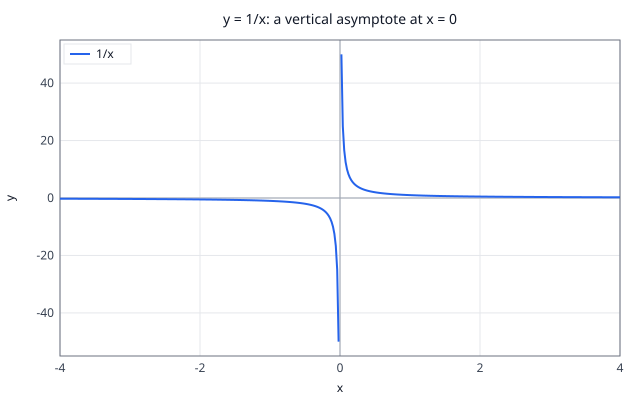

> `title`: A copy of plot p with a title or axis labels.

In [6]:
labels(title(plot(1/x, x, -4, 4), "y = 1/x: a vertical asymptote at x = 0"), "x", "y")

The lines the curve approaches are called **asymptotes**: the vertical line $x = 0$ and the horizontal line $y = 0$.

## 3. Moving and stretching a graph

Starting from a graph of $f(x)$, four simple changes move or stretch it:

| new function | effect on the graph |
|---|---|
| $f(x) + k$ | moves it **up** by $k$ |
| $f(x - h)$ | moves it **right** by $h$ |
| $a\,f(x)$ | stretches it **vertically** by $a$ (and flips it if $a < 0$) |
| $f(b\,x)$ | squeezes it **horizontally** by $b$ |

The surprising one is $f(x - h)$: a *minus* moves the graph to the *right*, because the new function reaches the old
value $f(0)$ when $x - h = 0$, that is at $x = h$. Here is $f(x) = x^2$ moved right by 2 and up by 1:

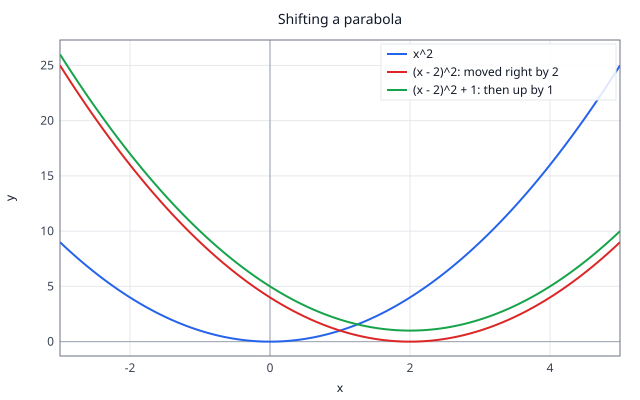

> `title`: A copy of plot p with a title or axis labels.

In [7]:
g(x) := x^2;
p = plot(g(x), g(x - 2), g(x - 2) + 1, x, -3, 5);
p = legend(p, "x^2", "(x - 2)^2: moved right by 2", "(x - 2)^2 + 1: then up by 1");
labels(title(p, "Shifting a parabola"), "x", "y")

That is why every parabola $y = a(x-h)^2 + k$ has its lowest (or highest) point, the **vertex**, at $(h, k)$. To find
the vertex of $x^2 - 6x + 11$, rewrite it in that form ("completing the square"):

In [8]:
expand((x - 3)^2 + 2)

x^2-6*x+11

> `expand`: Multiplies out products and powers.

So $x^2 - 6x + 11 = (x - 3)^2 + 2$ has its vertex at $(3, 2)$.

## 4. Exponentials and logarithms

In $2^x$ the variable is in the exponent. Such **exponential functions** grow faster than any power of $x$. Every time
$x$ increases by 1, $2^x$ doubles. The most important one uses the base $e \approx 2.718$: `exp(x)` is $e^x$.

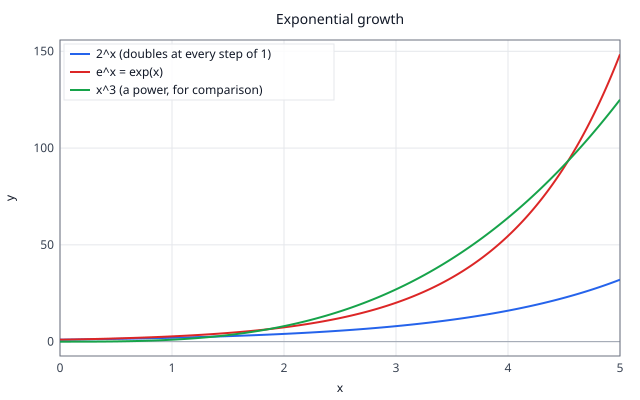

> `title`: A copy of plot p with a title or axis labels.

In [9]:
p = plot(2^x, exp(x), x^3, x, 0, 5);
p = legend(p, "2^x (doubles at every step of 1)", "e^x = exp(x)", "x^3 (a power, for comparison)");
labels(title(p, "Exponential growth"), "x", "y")

For a while $x^3$ is ahead, but the exponentials win in the end ($e^x$ passes $x^3$ near $x = 4.5$).

The **logarithm** undoes the exponential: $\log(e^x) = x$ and $e^{\log x} = x$. In Galileo `log` is the natural
logarithm (base $e$). The logarithm to base $b$ is $\log(x)/\log(b)$.

In [10]:
log(exp(3))
exp(log(y))
log(1000)/log(10)
log(1000)

3

> `log`: Natural logarithm.

y

> `exp`: Exponential function.

3

3*log(10)

> `log`: Natural logarithm.

$\log_{10} 1000 = 3$ because $10^3 = 1000$; Galileo sees that $1000 = 10^3$, so $\log 1000 = 3\log 10$.

The graph of an inverse function is the mirror image of the original in the diagonal line $y = x$, because swapping
$x$ and $y$ swaps the roles of input and output. A mirror image only looks like one when both axes use the same
scale, which `plot` does not promise. `parametric(X, Y, t, from, to)` draws the points $(X, Y)$ as $t$ runs from
*from* to *to*, with **equal scales** on both axes ([geometry](09-geometry-and-conics.ipynb) uses it a lot). The point
$(t, e^t)$ traces $y = e^x$; swapping the coordinates, $(e^t, t)$, traces its mirror image $y = \log x$; and
`show(...)` overlays plots:

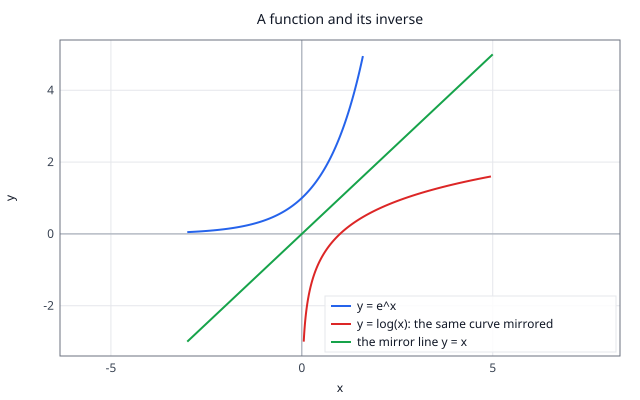

> `title`: A copy of plot p with a title or axis labels.

In [11]:
p1 = parametric(t, exp(t), t, -3, 1.6);
p2 = parametric(exp(t), t, t, -3, 1.6);
p3 = parametric(t, t, t, -3, 5);
p = legend(show(p1, p2, p3), "y = e^x", "y = log(x): the same curve mirrored", "the mirror line y = x");
labels(title(p, "A function and its inverse"), "x", "y")

## 5. Where do two graphs cross?

Two graphs cross where their values are equal. For $y = x^2$ and $y = x + 2$ that is the equation $x^2 = x + 2$:

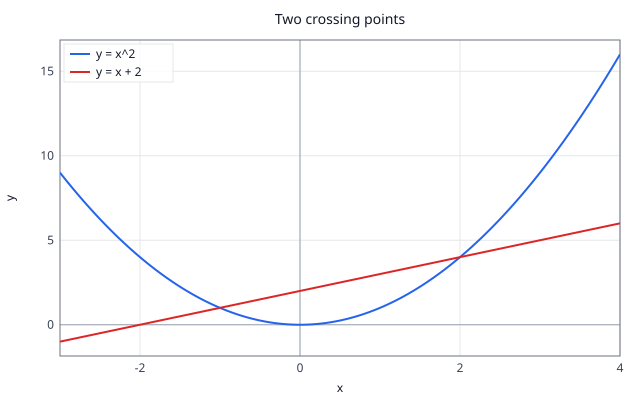

> `title`: A copy of plot p with a title or axis labels.

-1	2

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

In [12]:
p = plot(x^2, x + 2, x, -3, 4);
p = legend(p, "y = x^2", "y = x + 2");
labels(title(p, "Two crossing points"), "x", "y")
solve(x^2 == x + 2, x)

The graphs cross at $x = -1$ and $x = 2$. Some equations have no formula for their solutions, for example
$\cos x = x$. Then `fsolve(equation, x, guess)` finds a numeric solution, starting its search at the guess (read
the guess off the graph):

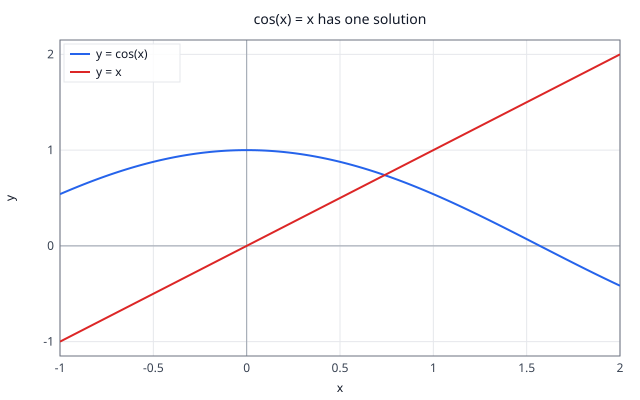

> `title`: A copy of plot p with a title or axis labels.

0.7390851332151607

> `fsolve`: A numeric solution of f = 0 near the guess (Newton's method).

In [13]:
p = plot(cos(x), x, x, -1, 2);
labels(title(legend(p, "y = cos(x)", "y = x"), "cos(x) = x has one solution"), "x", "y")
fsolve(cos(x) == x, x, 0.7)

## Summary

* `plot(f1, f2, ..., x, from, to)` draws curves; `labels`, `title` and `legend` make the plot readable.
* Read zeros, turning points and asymptotes off a graph; confirm them with `solve`.
* $f(x - h) + k$ moves a graph right by $h$ and up by $k$.
* Exponentials grow faster than powers; `log` is the inverse of `exp`.
* Crossing points solve $f(x) = g(x)$: `solve` exactly, `fsolve` numerically.

**Try it:** plot $\sin(x)$, $\sin(x) + 1$, $2\sin(x)$ and $\sin(2x)$ together and explain each change.

Next: [Polynomials](04-polynomials.ipynb).

## Sources

1. J. Stewart, *Precalculus: Mathematics for Calculus*, 7th ed., Cengage (2015). Chapter 2 (functions and transformations of graphs) and Chapter 4 (exponential and logarithmic functions).